<a href="https://colab.research.google.com/github/nhentze1/Minimum-Wages-and-Business-Models-Company-Owned-vs.-Franchise-Restaurants/blob/main/minwageDiD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Minimum Wages and Restaurant Business Models

This notebook replicates an employment benchmark from Card and Krueger (1994) and extends the analysis to ownership-specific employment, prices, and daily opening hours.

## Data Access and Setup

Use a Python 3.12 environment as the notebook kernel. The first code cell installs the required packages into that kernel. It loads **CardKrueger_1994_Fastfood.xlsx** from the working directory when available; otherwise it downloads the workbook from the public GitHub repository.

Run all cells in order. Package installation requires internet access; the analysis uses the local workbook when it is present. The original workbook has German sheet names and metadata; all explanations, variable definitions, plots, and generated conclusions in this notebook are in English.

## Load Libraries and Data

The setup cell uses `%pip` so installation targets the selected notebook kernel. Data-loading errors stop execution rather than leaving undefined analysis objects.

In [12]:
%pip install pandas numpy matplotlib seaborn openpyxl statsmodels -q
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)

url_to_excel = "https://raw.githubusercontent.com/nhentze1/Minimum-Wages-and-Business-Models-Company-Owned-vs.-Franchise-Restaurants/main/CardKrueger_1994_Fastfood.xlsx"
local_file = Path("CardKrueger_1994_Fastfood.xlsx")
data_source = local_file if local_file.exists() else url_to_excel
excel_file = pd.ExcelFile(data_source)
df = pd.read_excel(excel_file, sheet_name="Daten")
print(f"Loaded {len(df)} restaurants from {data_source}.")
display(df.head())


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Loaded 410 restaurants from CardKrueger_1994_Fastfood.xlsx.


,sheet,chain,co_owned,state,southj,centralj,northj,pa1,pa2,shore,...,firstin2,special2,meals2,open2r,hrsopen2,psoda2,pfry2,pentree2,nregs2,nregs112
0,46,1,0,0,0,0,0,1,0,0,...,0.08,1.0,2.0,6.5,16.5,1.03,NaN,0.94,4.0,4.0
1,49,2,0,0,0,0,0,1,0,0,...,0.05,0.0,2.0,10.0,13.0,1.01,0.89,2.35,4.0,4.0
2,506,2,1,0,0,0,0,1,0,0,...,0.25,NaN,1.0,11.0,11.0,0.95,0.74,2.33,4.0,3.0
3,56,4,1,0,0,0,0,1,0,0,...,0.15,0.0,2.0,10.0,12.0,0.92,0.79,0.87,2.0,2.0
4,61,4,1,0,0,0,0,1,0,0,...,0.15,0.0,2.0,10.0,12.0,1.01,0.84,0.95,2.0,2.0


## Workbook Structure and English Variable Guide

The workbook contains data, source information, and a codebook. The guide below documents the analysis variables in English without reproducing the workbook's German metadata. Original variable and sheet identifiers are retained for reproducibility.

In [6]:
# Show the names of all sheets in the file
if 'excel_file' in globals():
    print("Available sheets in the file:", excel_file.sheet_names)
else:
    print("Please run the setup cells above first.")

Available sheets in the file: ['Info', 'Daten', 'Codebuch']


In [7]:
variable_definitions = pd.DataFrame([
    ("sheet", "Unique restaurant ID"),
    ("state", "1 = New Jersey; 0 = Pennsylvania"),
    ("co_owned", "1 = Company-owned; 0 = Franchise"),
    ("chain", "1 = Burger King; 2 = KFC; 3 = Roy Rogers; 4 = Wendy's"),
    ("empft / emppt / nmgrs", "Full-time workers / part-time workers / managers"),
    ("psoda / pfry / pentree", "Tax-inclusive price: medium soda / small fries / main entree (USD)"),
    ("hrsopen", "Daily opening hours"),
    ("wage_st", "Starting hourly wage (USD)"),
    ("status2", "0 = Refused; 1 = Interviewed; 2 = Renovation; 3 = Permanently closed; 4 = Road construction; 5 = Fire"),
    ("Suffix 2", "Follow-up survey; no suffix denotes baseline"),
], columns=["Variable", "English definition"])
display(variable_definitions)

,Variable,English definition
0,sheet,Unique restaurant ID
1,state,1 = New Jersey; 0 = Pennsylvania
2,co_owned,1 = Company-owned; 0 = Franchise
3,chain,1 = Burger King; 2 = KFC; 3 = Roy Rogers; 4 = ...
4,empft / emppt / nmgrs,Full-time workers / part-time workers / managers
5,psoda / pfry / pentree,Tax-inclusive price: medium soda / small fries...
6,hrsopen,Daily opening hours
7,wage_st,Starting hourly wage (USD)
8,status2,0 = Refused; 1 = Interviewed; 2 = Renovation; ...
9,Suffix 2,Follow-up survey; no suffix denotes baseline


### Setup Completed Successfully

The data is loaded and stored in the variable `df`. We can now proceed with the exploratory data analysis and Difference-in-Differences (DiD) estimations.

In [8]:
# Confirming that the data is ready
if 'df' in globals():
    print(f"Ready for analysis! The dataset contains {df.shape[0]} rows and {df.shape[1]} columns.")
else:
    print("Please run the setup cells above to load the data.")

Ready for analysis! The dataset contains 410 rows and 46 columns.


## Research Design and Outcome Definitions

On April 1, 1992, New Jersey increased its minimum wage from USD 4.25 to USD 5.05 per hour; Pennsylvania retained USD 4.25. The first survey was in February/March and the second in November/December 1992.

We compare before-to-after changes in New Jersey with changes in Pennsylvania, separately for franchise and company-owned restaurants. The ownership contrast is a difference-in-difference-in-differences (DDD): franchise DiD minus company-owned DiD.

- **Employment:** full-time workers + managers + 0.5 x part-time workers, in full-time equivalents (FTE). A missing component makes the total missing. Permanently closed restaurants have zero follow-up employment; temporary closures and refusals are not automatically set to zero.
- **Prices:** the sum of a medium soda, small fries, and main entree, in nominal tax-inclusive USD. All three components must be observed. This is a fixed item basket, not a transaction-weighted price index.
- **Operations:** reported daily opening hours. Main price and hours estimates require an interviewed restaurant at follow-up; they describe the observed operating sample rather than all original restaurants.

Each outcome uses its own sample with both waves observed. We report sample counts and attrition rather than treating missing values as zeros. Ownership and chain are measured at baseline; ownership transitions are not observed.

In [9]:
analysis = df.copy()
required_columns = [
    "sheet", "chain", "state", "co_owned", "status2",
    "empft", "nmgrs", "emppt", "empft2", "nmgrs2", "emppt2",
    "psoda", "pfry", "pentree", "psoda2", "pfry2", "pentree2",
    "hrsopen", "hrsopen2", "wage_st", "wage_st2",
]
assert set(required_columns).issubset(analysis.columns), "Required variables are missing."
analysis[required_columns] = analysis[required_columns].apply(pd.to_numeric, errors="raise")
assert analysis["sheet"].is_unique, "Restaurant IDs must be unique."
assert analysis[["sheet", "chain", "state", "co_owned", "status2"]].notna().all().all()
assert analysis["state"].isin([0, 1]).all()
assert analysis["co_owned"].isin([0, 1]).all()
assert analysis["chain"].isin([1, 2, 3, 4]).all()
assert analysis["status2"].isin([0, 1, 2, 3, 4, 5]).all()

analysis["franchise"] = 1 - analysis["co_owned"]
analysis["state_name"] = analysis["state"].map({0: "Pennsylvania", 1: "New Jersey"})
analysis["ownership"] = analysis["franchise"].map({0: "Company-owned", 1: "Franchise"})
analysis["chain_name"] = analysis["chain"].map({1: "Burger King", 2: "KFC", 3: "Roy Rogers", 4: "Wendy's"})
status_names = {
    0: "Refused interview", 1: "Interviewed", 2: "Closed for renovation",
    3: "Permanently closed", 4: "Closed for road construction",
    5: "Closed after shopping-center fire",
}
analysis["follow_up_status"] = analysis["status2"].map(status_names)

for wave, suffix in [("before", ""), ("after", "2")]:
    employment_columns = [f"empft{suffix}", f"nmgrs{suffix}", f"emppt{suffix}"]
    price_columns = [f"psoda{suffix}", f"pfry{suffix}", f"pentree{suffix}"]
    analysis[f"employment_{wave}"] = analysis[employment_columns].mul([1, 1, 0.5]).sum(axis=1, min_count=3)
    analysis[f"meal_price_{wave}"] = analysis[price_columns].sum(axis=1, min_count=3)
    analysis[f"hours_{wave}"] = analysis[f"hrsopen{suffix}"]

analysis.loc[analysis["status2"].eq(3), "employment_after"] = 0.0
analysis.loc[analysis["status2"].ne(1), ["meal_price_after", "hours_after"]] = np.nan
outcomes = {
    "employment": "Employment (FTE)",
    "meal_price": "Meal basket price (USD)",
    "hours": "Daily opening hours",
}
samples = {}
for outcome in outcomes:
    before, after = f"{outcome}_before", f"{outcome}_after"
    values = analysis[[before, after]]
    assert (values.ge(0) | values.isna()).all().all(), f"Negative values in {outcome}."
    sample = analysis.dropna(subset=[before, after]).copy()
    sample["change"] = sample[after] - sample[before]
    assert sample.groupby(["state", "franchise"]).size().size == 4
    samples[outcome] = sample

benchmark = analysis.groupby("state_name")[["employment_before", "employment_after"]].mean()
expected = pd.DataFrame(
    {"employment_before": [20.44, 23.33], "employment_after": [21.03, 21.17]},
    index=["New Jersey", "Pennsylvania"],
)
assert np.allclose(benchmark.loc[expected.index], expected, atol=0.005), "Published employment benchmark does not match."
print("Employment benchmark reproduced using all available observations in each wave:")
display(benchmark.round(2))
print("Restaurants by state and baseline ownership:")
display(pd.crosstab(analysis["state_name"], analysis["ownership"]))
print("Follow-up status by state:")
display(pd.crosstab(analysis["follow_up_status"], analysis["state_name"]))
print("Paired sample sizes:")
display(pd.DataFrame({outcomes[outcome]: sample.groupby(["state_name", "ownership"]).size() for outcome, sample in samples.items()}))
print("Restaurants by chain, state, and ownership:")
display(pd.crosstab([analysis["chain_name"], analysis["state_name"]], analysis["ownership"]))

Employment benchmark reproduced using all available observations in each wave:


,employment_before,employment_after
state_name,,
New Jersey,20.44,21.03
Pennsylvania,23.33,21.17


Restaurants by state and baseline ownership:


ownership,Company-owned,Franchise
state_name,,
New Jersey,113,218
Pennsylvania,28,51


Follow-up status by state:


state_name,New Jersey,Pennsylvania
follow_up_status,,
Closed after shopping-center fire,1,0
Closed for renovation,2,0
Closed for road construction,1,0
Interviewed,321,78
Permanently closed,5,1
Refused interview,1,0


Paired sample sizes:


Employment (FTE)  Meal basket price (USD)  \
state_name   ownership                                                  
New Jersey   Company-owned               108                       92   
             Franchise                   201                      195   
Pennsylvania Company-owned                26                       26   
             Franchise                    49                       42   

                            Daily opening hours  
state_name   ownership                           
New Jersey   Company-owned                  108  
             Franchise                      212  
Pennsylvania Company-owned                   28  
             Franchise                       50

Restaurants by chain, state, and ownership:


ownership                 Company-owned  Franchise
chain_name  state_name                            
Burger King New Jersey               25        111
            Pennsylvania              0         35
KFC         New Jersey               28         40
            Pennsylvania              8          4
Roy Rogers  New Jersey               56         26
            Pennsylvania             12          5
Wendy's     New Jersey                4         41
            Pennsylvania              8          7

## Descriptive Changes and Difference-in-Differences

The plots use the same paired restaurants before and after within each outcome, avoiding changes driven solely by a different observed sample in each wave. A two-point line is descriptive, not evidence that pre-treatment trends were parallel.

For each outcome, we estimate a first-difference regression:

$$\Delta Y_i = \alpha + \beta\,NJ_i + \gamma\,Franchise_i + \delta\,(NJ_i \times Franchise_i) + \varepsilon_i.$$

The company-owned DiD is $\beta$, the franchise DiD is $\beta + \delta$, and the ownership difference (DDD) is $\delta$. First-differencing removes time-invariant restaurant effects; this is the two-period counterpart of a restaurant-fixed-effects model with the relevant post-period interactions.

A negative DDD means a more negative franchise response in FTE or opening hours; a positive price DDD means a larger franchise price increase. These are relative effects: a negative DDD does not necessarily mean franchise employment or hours fell in absolute terms.

We report two-sided 95% HC3 heteroskedasticity-robust confidence intervals and unadjusted p-values. With one change observation per restaurant, HC3 treats restaurants as independent. **These intervals do not account for state-level common shocks and are not reliable policy-level inference with only two states.** Results are exploratory, including across the three outcomes.

restaurants  before  \
outcome                 state_name   ownership                            
Employment (FTE)        New Jersey   Company-owned          108  19.683   
                                     Franchise              201  20.832   
                        Pennsylvania Company-owned           26  18.433   
                                     Franchise               49  26.005   
Meal basket price (USD) New Jersey   Company-owned           92   3.419   
                                     Franchise              195   3.332   
                        Pennsylvania Company-owned           26   3.343   
                                     Franchise               42   2.930   
Daily opening hours     New Jersey   Company-owned          108  14.778   
                                     Franchise              212  14.229   
                        Pennsylvania Company-owned           28  12.750   
                                     Franchise               50  15.550   

                                                     after  change  
outcome                 state_name   ownership                      
Employment (FTE)        New Jersey   Company-owned  19.671  -0.012  
                                     Franchise      21.556   0.724  
                        Pennsylvania Company-owned  16.385  -2.048  
                                     Franchise      23.597  -2.408  
Meal basket price (USD) New Jersey   Company-owned   3.499   0.080  
                                     Franchise       3.393   0.061  
                        Pennsylvania Company-owned   3.240  -0.103  
                                     Franchise       2.939   0.009  
Daily opening hours     New Jersey   Company-owned  14.634  -0.144  
                                     Franchise      14.303   0.074  
                        Pennsylvania Company-owned  12.768   0.018  
                                     Franchise      15.710   0.160

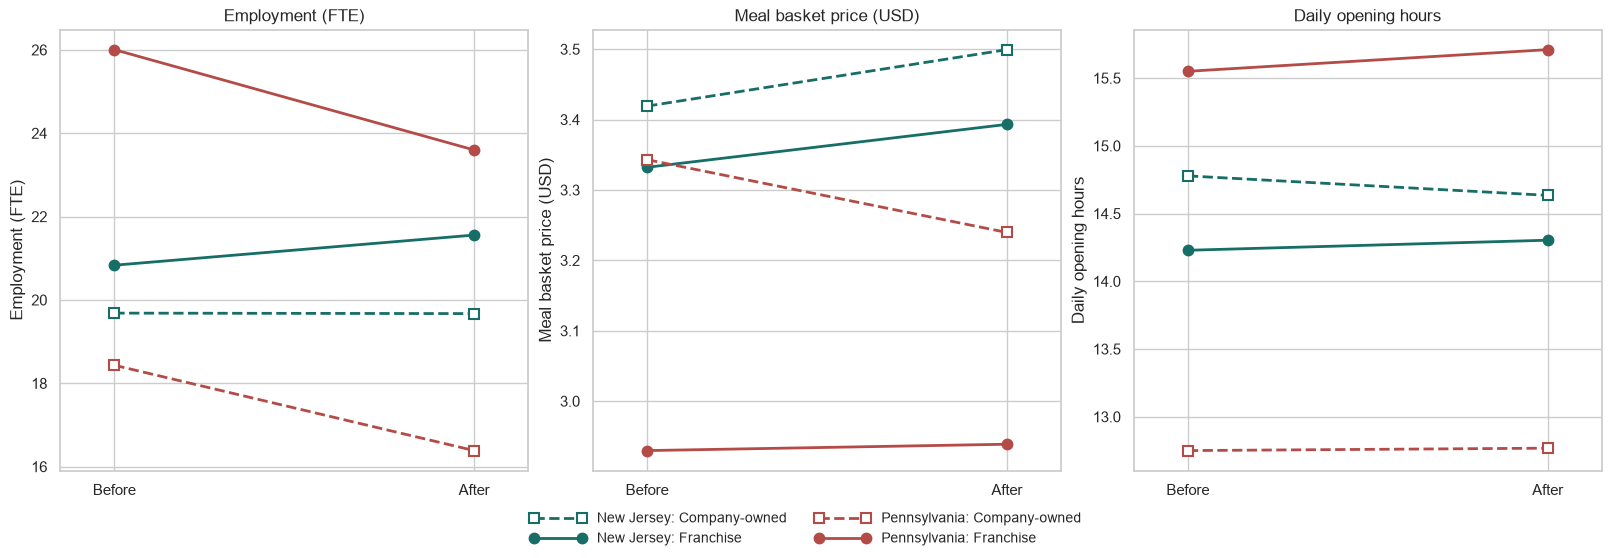

Pooled DiD on outcome-specific paired samples (not an exact replication of every paper specification):


,Outcome,Effect,Estimate,Robust SE,CI lower,CI upper,p-value,Restaurants
0,Employment (FTE),Pooled DiD,2.7500,1.3505,0.1031,5.3969,0.0417,384
1,Meal basket price (USD),Pooled DiD,0.1011,0.0439,0.0150,0.1872,0.0214,355
2,Daily opening hours,Pooled DiD,-0.1082,0.1032,-0.3105,0.0941,0.2946,398


Manual group-mean calculations, verified against regression coefficients:


,Outcome,Company-owned DiD,Franchise DiD,DDD
0,Employment (FTE),2.0365,3.1318,1.0953
1,Meal basket price (USD),0.1837,0.0519,-0.1318
2,Daily opening hours,-0.1614,-0.0857,0.0757


Ownership-specific effects with exploratory restaurant-level HC3 uncertainty:


,Outcome,Effect,Estimate,Robust SE,CI lower,CI upper,p-value,Restaurants
0,Employment (FTE),Company-owned DiD,2.0365,1.5722,-1.0450,5.1180,0.1952,384
1,Employment (FTE),Franchise DiD,3.1318,1.9114,-0.6145,6.8781,0.1013,384
2,Employment (FTE),Franchise minus company-owned (DDD),1.0953,2.4749,-3.7555,5.9461,0.6581,384
3,Meal basket price (USD),Company-owned DiD,0.1837,0.0790,0.0288,0.3385,0.0201,355
4,Meal basket price (USD),Franchise DiD,0.0519,0.0513,-0.0487,0.1525,0.3116,355
5,Meal basket price (USD),Franchise minus company-owned (DDD),-0.1318,0.0942,-0.3164,0.0529,0.1620,355
6,Daily opening hours,Company-owned DiD,-0.1614,0.2052,-0.5636,0.2408,0.4316,398
7,Daily opening hours,Franchise DiD,-0.0857,0.1166,-0.3142,0.1428,0.4623,398
8,Daily opening hours,Franchise minus company-owned (DDD),0.0757,0.2360,-0.3869,0.5383,0.7485,398


All three manual DiD/DDD identities match the regression estimates.


In [13]:
descriptive_tables = []
figure, axes = plt.subplots(1, 3, figsize=(16, 5.5), constrained_layout=True)
state_colors = {"New Jersey": "#166e67", "Pennsylvania": "#b44b47"}
ownership_styles = {"Company-owned": "--", "Franchise": "-"}
ownership_markers = {"Company-owned": "s", "Franchise": "o"}
for axis, (outcome, label) in zip(axes, outcomes.items()):
    sample = samples[outcome]
    grouped = sample.groupby(["state_name", "ownership"])
    summary = grouped.agg(
        restaurants=("sheet", "size"),
        before=(f"{outcome}_before", "mean"),
        after=(f"{outcome}_after", "mean"),
        change=("change", "mean"),
    )
    descriptive_tables.append(summary.assign(outcome=label).reset_index())
    for (state_name, ownership), values in summary.iterrows():
        axis.plot(
            [0, 1], [values["before"], values["after"]],
            marker=ownership_markers[ownership], color=state_colors[state_name],
            markerfacecolor="white" if ownership == "Company-owned" else state_colors[state_name],
            markersize=7, markeredgewidth=1.5, linewidth=2,
            linestyle=ownership_styles[ownership],
            label=f"{state_name}: {ownership}",
        )
    axis.set_xticks([0, 1], ["Before", "After"])
    axis.set_xlim(-0.15, 1.15)
    axis.set_title(label)
    axis.set_ylabel(label)
legend_handles, legend_labels = axes[0].get_legend_handles_labels()
figure.legend(
    legend_handles, legend_labels, loc="outside lower center", ncol=2,
    fontsize=10, handlelength=4, numpoints=2, columnspacing=2,
    frameon=False,
 )
display(pd.concat(descriptive_tables, ignore_index=True).set_index(["outcome", "state_name", "ownership"]).round(3))
plt.show()

def contrast_row(model, expression, outcome_label, effect_label, specification="Unadjusted"):
    contrast = model.t_test(expression)
    interval = np.asarray(contrast.conf_int()).reshape(-1)
    return {
        "Outcome": outcome_label,
        "Specification": specification,
        "Effect": effect_label,
        "Estimate": np.asarray(contrast.effect).item(),
        "Robust SE": np.asarray(contrast.sd).item(),
        "CI lower": interval[0],
        "CI upper": interval[1],
        "p-value": np.asarray(contrast.pvalue).item(),
        "Restaurants": int(model.nobs),
    }

models = {}
effect_rows = []
pooled_rows = []
manual_rows = []
for outcome, label in outcomes.items():
    sample = samples[outcome]
    model = smf.ols("change ~ state * franchise", data=sample).fit(cov_type="HC3")
    assert np.linalg.matrix_rank(model.model.exog) == model.model.exog.shape[1]
    models[outcome] = model
    for expression, effect_label in [
        ("state", "Company-owned DiD"),
        ("state + state:franchise", "Franchise DiD"),
        ("state:franchise", "Franchise minus company-owned (DDD)"),
    ]:
        effect_rows.append(contrast_row(model, expression, label, effect_label))
    means = sample.groupby(["state", "franchise"])["change"].mean()
    company_did = means.loc[(1, 0)] - means.loc[(0, 0)]
    franchise_did = means.loc[(1, 1)] - means.loc[(0, 1)]
    ddd = franchise_did - company_did
    assert np.isclose(model.params["state"], company_did)
    assert np.isclose(model.params["state"] + model.params["state:franchise"], franchise_did)
    assert np.isclose(model.params["state:franchise"], ddd)
    manual_rows.append({"Outcome": label, "Company-owned DiD": company_did, "Franchise DiD": franchise_did, "DDD": ddd})
    pooled = smf.ols("change ~ state", data=sample).fit(cov_type="HC3")
    pooled_rows.append(contrast_row(pooled, "state", label, "Pooled DiD"))

pooled_results = pd.DataFrame(pooled_rows)
results = pd.DataFrame(effect_rows)
print("Pooled DiD on outcome-specific paired samples (not an exact replication of every paper specification):")
display(pooled_results.drop(columns="Specification").round(4))
print("Manual group-mean calculations, verified against regression coefficients:")
display(pd.DataFrame(manual_rows).round(4))
print("Ownership-specific effects with exploratory restaurant-level HC3 uncertainty:")
display(results.drop(columns="Specification").round(4))
assert np.isfinite(results[["Estimate", "Robust SE", "CI lower", "CI upper", "p-value"]].to_numpy()).all()
print("All three manual DiD/DDD identities match the regression estimates.")

## Sensitivity Checks

1. **Chain-adjusted changes:** add chain indicators to the first-difference regression. These allow common chain-specific time shocks, not chain-specific treatment effects. They do not resolve missing ownership-by-state cells within a chain.
2. **Employment without permanent closures:** exclude permanently closed restaurants to show how the extensive margin affects the estimate. This changes the estimand and is not a correction for non-random survival.
3. **Opening hours including permanent closures:** assign zero follow-up hours to permanent closures only. Temporary closures, refusals, and other missing hours remain missing.
4. **Log meal-price changes:** estimate 100 times the change in log basket prices for strictly positive paired prices. Units are log points, approximately percentage points for small changes, rather than dollars.

The table reports only the franchise-minus-company DDD for each specification. Different samples, units, and assumptions mean these rows should not be pooled into one estimate.

In [11]:
sensitivity_rows = results.loc[results["Effect"].eq("Franchise minus company-owned (DDD)")].to_dict("records")
for outcome, label in outcomes.items():
    adjusted = smf.ols("change ~ state * franchise + C(chain)", data=samples[outcome]).fit(cov_type="HC3")
    assert np.linalg.matrix_rank(adjusted.model.exog) == adjusted.model.exog.shape[1]
    sensitivity_rows.append(contrast_row(adjusted, "state:franchise", label, "Franchise minus company-owned (DDD)", "Chain-adjusted changes"))

employment_survivors = samples["employment"].loc[samples["employment"]["status2"].ne(3)].copy()
hours_with_closures = analysis.copy()
hours_with_closures.loc[hours_with_closures["status2"].eq(3), "hours_after"] = 0.0
hours_with_closures = hours_with_closures.dropna(subset=["hours_before", "hours_after"]).copy()
hours_with_closures["change"] = hours_with_closures["hours_after"] - hours_with_closures["hours_before"]
log_prices = samples["meal_price"].loc[
    samples["meal_price"][["meal_price_before", "meal_price_after"]].gt(0).all(axis=1)
].copy()
log_prices["change"] = 100 * (np.log(log_prices["meal_price_after"]) - np.log(log_prices["meal_price_before"]))

for sample, label, specification in [
    (employment_survivors, outcomes["employment"], "Exclude permanent closures"),
    (hours_with_closures, outcomes["hours"], "Permanent closures have zero hours"),
    (log_prices, "Meal basket price (100 log points)", "Positive paired prices"),
]:
    assert sample.groupby(["state", "franchise"]).size().size == 4
    sensitivity_model = smf.ols("change ~ state * franchise", data=sample).fit(cov_type="HC3")
    sensitivity_rows.append(contrast_row(sensitivity_model, "state:franchise", label, "Franchise minus company-owned (DDD)", specification))

sensitivity_results = pd.DataFrame(sensitivity_rows)
assert np.isfinite(sensitivity_results[["Estimate", "Robust SE", "CI lower", "CI upper", "p-value"]].to_numpy()).all()
display(sensitivity_results.drop(columns="Effect").round(4))

retention_rows = []
for outcome, label in outcomes.items():
    retained = analysis["sheet"].isin(samples[outcome]["sheet"])
    retention = analysis.assign(retained=retained).groupby(["state_name", "ownership"]).agg(
        original_restaurants=("sheet", "size"),
        paired_restaurants=("retained", "sum"),
    )
    retention["excluded_restaurants"] = retention["original_restaurants"] - retention["paired_restaurants"]
    retention["retention_percent"] = 100 * retention["paired_restaurants"] / retention["original_restaurants"]
    retention_rows.append(retention.assign(outcome=label).reset_index())
print("Outcome-specific retention by state and ownership:")
display(pd.concat(retention_rows, ignore_index=True).set_index(["outcome", "state_name", "ownership"]).round(1))

display(Markdown("## Results Summary"))
ddd_results = results.loc[results["Effect"].eq("Franchise minus company-owned (DDD)")]
summary_lines = []
for _, result in ddd_results.iterrows():
    interval_description = "includes zero" if result["CI lower"] <= 0 <= result["CI upper"] else "excludes zero"
    summary_lines.append(
        f"- **{result['Outcome']}:** franchise minus company-owned DiD = {result['Estimate']:+.3f}; "
        f"exploratory HC3 95% CI [{result['CI lower']:.3f}, {result['CI upper']:.3f}], which {interval_description}; "
        f"{int(result['Restaurants'])} paired restaurants."
    )
display(Markdown("\n".join(summary_lines)))
display(Markdown(
    "These estimates do not establish that the business models responded differently. "
    "An interval containing zero is not evidence that the effects are identical. "
    "Compare the sensitivity table before drawing substantive conclusions; "
    "restaurant-level uncertainty does not solve the two-state policy-inference problem."
))

,Outcome,Specification,Estimate,Robust SE,CI lower,CI upper,p-value,Restaurants
0,Employment (FTE),Unadjusted,1.0953,2.4749,-3.7555,5.9461,0.6581,384
1,Meal basket price (USD),Unadjusted,-0.1318,0.0942,-0.3164,0.0529,0.1620,355
2,Daily opening hours,Unadjusted,0.0757,0.2360,-0.3869,0.5383,0.7485,398
3,Employment (FTE),Chain-adjusted changes,1.1417,2.4198,-3.6010,5.8844,0.6371,384
4,Meal basket price (USD),Chain-adjusted changes,-0.2084,0.1000,-0.4043,-0.0125,0.0371,355
5,Daily opening hours,Chain-adjusted changes,0.0674,0.2115,-0.3471,0.4819,0.7500,398
6,Employment (FTE),Exclude permanent closures,0.5422,2.4778,-4.3141,5.3985,0.8268,378
7,Daily opening hours,Permanent closures have zero hours,0.5581,0.4234,-0.2718,1.3881,0.1875,404
8,Meal basket price (100 log points),Positive paired prices,-4.4612,2.8495,-10.0461,1.1238,0.1174,355


Outcome-specific retention by state and ownership:


original_restaurants  \
outcome                 state_name   ownership                             
Employment (FTE)        New Jersey   Company-owned                   113   
                                     Franchise                       218   
                        Pennsylvania Company-owned                    28   
                                     Franchise                        51   
Meal basket price (USD) New Jersey   Company-owned                   113   
                                     Franchise                       218   
                        Pennsylvania Company-owned                    28   
                                     Franchise                        51   
Daily opening hours     New Jersey   Company-owned                   113   
                                     Franchise                       218   
                        Pennsylvania Company-owned                    28   
                                     Franchise                        51   

                                                    paired_restaurants  \
outcome                 state_name   ownership                           
Employment (FTE)        New Jersey   Company-owned                 108   
                                     Franchise                     201   
                        Pennsylvania Company-owned                  26   
                                     Franchise                      49   
Meal basket price (USD) New Jersey   Company-owned                  92   
                                     Franchise                     195   
                        Pennsylvania Company-owned                  26   
                                     Franchise                      42   
Daily opening hours     New Jersey   Company-owned                 108   
                                     Franchise                     212   
                        Pennsylvania Company-owned                  28   
                                     Franchise                      50   

                                                    excluded_restaurants  \
outcome                 state_name   ownership                             
Employment (FTE)        New Jersey   Company-owned                     5   
                                     Franchise                        17   
                        Pennsylvania Company-owned                     2   
                                     Franchise                         2   
Meal basket price (USD) New Jersey   Company-owned                    21   
                                     Franchise                        23   
                        Pennsylvania Company-owned                     2   
                                     Franchise                         9   
Daily opening hours     New Jersey   Company-owned                     5   
                                     Franchise                         6   
                        Pennsylvania Company-owned                     0   
                                     Franchise                         1   

                                                    retention_percent  
outcome                 state_name   ownership                         
Employment (FTE)        New Jersey   Company-owned               95.6  
                                     Franchise                   92.2  
                        Pennsylvania Company-owned               92.9  
                                     Franchise                   96.1  
Meal basket price (USD) New Jersey   Company-owned               81.4  
                                     Franchise                   89.4  
                        Pennsylvania Company-owned               92.9  
                                     Franchise                   82.4  
Daily opening hours     New Jersey   Company-owned               95.6  
                                     Franchise                   97.2  
                     

## Results Summary

- **Employment (FTE):** franchise minus company-owned DiD = +1.095; exploratory HC3 95% CI [-3.756, 5.946], which includes zero; 384 paired restaurants.
- **Meal basket price (USD):** franchise minus company-owned DiD = -0.132; exploratory HC3 95% CI [-0.316, 0.053], which includes zero; 355 paired restaurants.
- **Daily opening hours:** franchise minus company-owned DiD = +0.076; exploratory HC3 95% CI [-0.387, 0.538], which includes zero; 398 paired restaurants.

These estimates do not establish that the business models responded differently. An interval containing zero is not evidence that the effects are identical. Compare the sensitivity table before drawing substantive conclusions; restaurant-level uncertainty does not solve the two-state policy-inference problem.

## Interpretation and Limitations

- **Employment:** the unadjusted ownership contrast does not support a clear claim that franchise restaurants reduced employment more than company-owned restaurants. The wide interval also does not establish equivalence.
- **Prices:** the direction is opposite to a larger franchise price increase. The chain-adjusted DDD has an exploratory HC3 interval below zero, whereas the unadjusted and log-price contrasts include zero. The price finding is specification-sensitive, not a robust causal conclusion.
- **Opening hours:** the point estimate changes when permanent closures are assigned zero hours; the ownership contrasts remain imprecise. Neither specification establishes a clear differential response.
- **Identification:** a causal DiD interpretation requires comparable untreated trends within ownership groups, no anticipation, and no relevant spillovers. The ownership DDD further requires no untreated New Jersey-versus-Pennsylvania trend difference specific to ownership. Only one pre-treatment wave is available, so these assumptions cannot be tested with pre-trend or event-study evidence.
- **Inference:** treatment varies at the state level, with only one treated and one control state. Restaurant-level HC3 intervals do not capture common state shocks. Conventional two-cluster standard errors are not a credible fix. P-values are exploratory and not adjusted for multiple outcomes or specifications.
- **Composition and selection:** ownership is not randomized, chain composition differs, and some chain-by-state ownership cells are empty. Chain indicators allow common chain-specific changes but cannot eliminate all ownership-related confounding. Prices and hours condition on observed follow-up interviews; outcome-specific missingness may be selective.
- **Measurement and scope:** survey measurement error, nominal tax-inclusive prices, unobserved product quality or sales weights, and the short two-wave horizon limit interpretation. These results concern this historical fast-food sample, not all restaurants or minimum-wage settings.

## Reference

Card, D., and Krueger, A. B. (1994). *Minimum Wages and Employment: A Case Study of the Fast-Food Industry in New Jersey and Pennsylvania.* American Economic Review, 84(4), 772-793.

The repository workbook is a conversion of the authors' public data. The employment means are checked against the workbook's published-paper benchmark; the ownership, price-basket, and hours specifications are extensions rather than a complete replication of every table in the paper.